# 5. Modelado con PySpark

En este capítulo entrenamos los mismos tipos de modelo con Spark MLlib en modo local (`local[p]`, un solo computador con $p$ núcleos). Describimos la configuración de la sesión y el *pipeline*, ajustamos el MLP con una rejilla evaluada en el día 29 y discutimos las limitaciones del `MultilayerPerceptronClassifier`. Las corridas se ejecutan con `python -m src.runner spark` y sus resultados quedan en `results/runs/pyspark/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

info = load_json(C.COMMON / "spark_info.json")
main = R.runs("PySpark", "main")
print(f"Spark {info['version']} | master {info['master']} | corridas principales: {len(main)}")

Resultados: results | prueba de humo: False
Spark 4.3.0 | master local[8] | corridas principales: 2


## 5.1 Sesión y configuración

Spark corre en modo local: el *driver* y los ejecutores comparten la máquina virtual de Java, y el paralelismo es el número de núcleos asignados. La configuración se fija en `src/config.py` y se registra en `results/common/spark_info.json`.

In [2]:
claves = ["spark.master", "spark.driver.memory", "spark.driver.maxResultSize", "spark.sql.shuffle.partitions",
          "spark.sql.adaptive.enabled", "spark.sql.execution.arrow.pyspark.enabled", "spark.local.dir"]
conf = {k: info["conf"].get(k, "") for k in claves}
conf["spark.local.dir"] = "data/spark_tmp"
conf["versión de Spark"] = info["version"]
conf["paralelismo por defecto"] = info["default_parallelism"]
display(pd.Series(conf, name="valor").to_frame())

,valor
spark.master,local[8]
spark.driver.memory,16g
spark.driver.maxResultSize,4g
spark.sql.shuffle.partitions,32
spark.sql.adaptive.enabled,true
spark.sql.execution.arrow.pyspark.enabled,true
spark.local.dir,data/spark_tmp
versión de Spark,4.3.0
paralelismo por defecto,8


La memoria del *driver* (16 GB) deja cerca de la mitad de la RAM del equipo para el sistema operativo y para el proceso de Python. Con 32 particiones de *shuffle*, cada tarea de agregación procesa una fracción manejable de los datos sin crear miles de tareas pequeñas, que en modo local solo añaden sobrecarga. La ejecución adaptativa (AQE) permite a Spark unir particiones pequeñas después de cada *shuffle*.

## 5.2 Pipeline de preprocesamiento

El preprocesamiento replica el de scikit-learn (sección 3.6). La agrupación de raras y la frecuencia se implementan con uniones contra tablas de conteo calculadas en entrenamiento; el resto son etapas de `pyspark.ml`:

```python
# hashing (LogisticRegression y MLP)
Pipeline(stages=[FeatureHasher(inputCols=CAT_COLS, outputCol="features", numFeatures=2**12)])

# frecuencia (GBTClassifier)
Pipeline(stages=[
    StringIndexer(inputCols=baja, outputCols=idx, handleInvalid="keep"),
    OneHotEncoder(inputCols=idx, outputCols=oh, dropLast=False, handleInvalid="keep"),
    VectorAssembler(inputCols=log_frecuencias, outputCol="_num"),
    StandardScaler(inputCol="_num", outputCol="_numz", withMean=True, withStd=True),
    VectorAssembler(inputCols=["_numz", *oh], outputCol="features"),
])
```

`handleInvalid="keep"` asigna un índice propio a las categorías que no aparecieron en entrenamiento, el equivalente de `__RARE__` para las variables de baja cardinalidad.

Los modelos son:

| Modelo | Clase | Entrada | Configuración |
|---|---|---|---|
| Regresión logística | `LogisticRegression` | Hashing $2^{12}$ | L-BFGS, `regParam` = $10^{-5}$, sin estandarización interna |
| Árboles potenciados | `GBTClassifier` | Frecuencia | 50 árboles de profundidad 5, `stepSize` = 0.1 |
| MLP | `MultilayerPerceptronClassifier` | Hashing $2^{12}$ | Capas `[d, ..., 2]` elegidas por rejilla |

Usamos $d = 2^{12}$, la menor dimensión de la guía, por una restricción del MLP de Spark que medimos en la sección 5.4.

## 5.3 Rejilla del MLP con validación temporal

`CrossValidator` y `TrainValidationSplit` reparten las filas al azar entre ajuste y evaluación, lo que rompería la validación temporal. Construimos la rejilla con `ParamGridBuilder` y evaluamos cada combinación de forma explícita en el día 29 con `BinaryClassificationEvaluator` (área bajo la curva ROC):

| Parámetro | Valores |
|---|---|
| `layers` | `[d, 10, 2]`, `[d, 50, 2]`, `[d, 100, 2]`, `[d, 128, 64, 2]` |
| `stepSize` | 0.1 y 0.01 |
| `maxIter` | 100 y 200 |
| `solver` | `l-bfgs` y `gd` |

Son 32 combinaciones. El costo de cada ajuste crece con el número de iteraciones y con el ancho de la primera capa oculta, por lo que la rejilla se evalúa sobre una muestra de entrenamiento menor que la principal. Después del primer ajuste, el código estima el tiempo de cada combinación y omite las que superan el presupuesto.

,capas,stepSize,maxIter,solver,AUC validación,ajuste (s),omitido
0,"[d, 128, 64, 2]",0.01,100,l-bfgs,0.6973,93.9401,False
1,"[d, 128, 64, 2]",0.10,100,l-bfgs,0.6973,87.7896,False
2,"[d, 100, 2]",0.10,100,l-bfgs,0.6895,65.5042,False
3,"[d, 100, 2]",0.01,100,l-bfgs,0.6895,64.2702,False
4,"[d, 128, 64, 2]",0.01,200,l-bfgs,0.6856,186.0191,False
5,"[d, 128, 64, 2]",0.10,200,l-bfgs,0.6856,181.8995,False
6,"[d, 50, 2]",0.01,100,l-bfgs,0.6841,44.0881,False
7,"[d, 50, 2]",0.10,100,l-bfgs,0.6841,54.9881,False
8,"[d, 100, 2]",0.10,200,l-bfgs,0.6745,129.8360,False
9,"[d, 100, 2]",0.01,200,l-bfgs,0.6745,131.4877,False


Muestra de la rejilla: 20 000 filas | d = 4096 | núcleos = 8


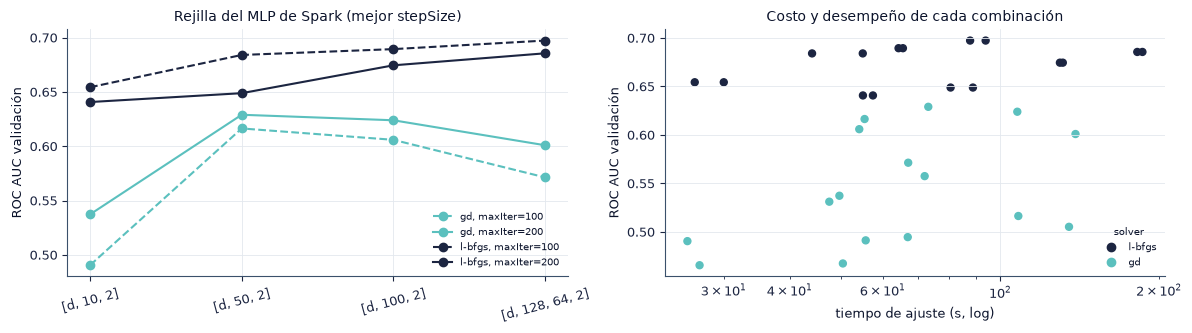

In [3]:
grid = load_json(C.COMMON / "spark_grid_mlp.json")
gr = pd.DataFrame(grid["resultados"])
gr["capas"] = gr["layers"].map(lambda l: "[d, " + ", ".join(map(str, l)) + ", 2]")
show = gr[["capas", "stepSize", "maxIter", "solver", "auc_val", "fit_s", "omitido"]].sort_values("auc_val", ascending=False)
display(show.rename(columns={"auc_val": "AUC validación", "fit_s": "ajuste (s)"}).reset_index(drop=True).round(4))
print(f"Muestra de la rejilla: {R.num(grid['n_train'])} filas | d = {grid['d']} | núcleos = {grid['cores']}")

ok = gr[~gr["omitido"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for (solver, mi), g in ok.groupby(["solver", "maxIter"]):
    g = g.groupby("capas", sort=False)["auc_val"].max()
    axes[0].plot(g.index, g.values, marker="o", label=f"{solver}, maxIter={mi}",
                 color="#1C2541" if solver == "l-bfgs" else "#5BC0BE", ls="-" if mi == max(ok["maxIter"]) else "--")
axes[0].set_ylabel("ROC AUC validación"); axes[0].set_title("Rejilla del MLP de Spark (mejor stepSize)"); axes[0].legend(fontsize=7)
axes[0].tick_params(axis="x", rotation=15)
axes[1].scatter(ok["fit_s"], ok["auc_val"], c=["#1C2541" if s == "l-bfgs" else "#5BC0BE" for s in ok["solver"]], s=25)
from matplotlib.lines import Line2D
axes[1].legend(handles=[Line2D([], [], ls="", marker="o", color="#1C2541", label="l-bfgs"), Line2D([], [], ls="", marker="o", color="#5BC0BE", label="gd")], fontsize=7, title="solver", title_fontsize=7)
axes[1].set_xscale("log"); axes[1].set_xlabel("tiempo de ajuste (s, log)"); axes[1].set_ylabel("ROC AUC validación"); axes[1].set_title("Costo y desempeño de cada combinación")
fig.tight_layout(); P.save(fig, "5_3_rejilla_spark"); plt.show()

In [4]:
bp = grid["best_params"]
gd, lb = ok[ok["solver"] == "gd"]["auc_val"], ok[ok["solver"] == "l-bfgs"]["auc_val"]
R.findings(
    f"La mejor combinación es `layers=[d, {', '.join(map(str, bp['layers']))}, 2]`, `stepSize={bp['stepSize']}`, `maxIter={bp['maxIter']}` y "
    f"`solver={bp['solver']}`, con un AUC de validación de {grid['best_auc_val']:.4f}. "
    + (f"El AUC medio con L-BFGS es {lb.mean():.4f} y con descenso de gradiente {gd.mean():.4f}. " if len(gd) and len(lb) else "")
    + (f"Se omitieron {int(gr['omitido'].sum())} combinaciones por presupuesto." if gr["omitido"].any() else "Todas las combinaciones se evaluaron dentro del presupuesto."),
    {"Preprocesamiento": "la rejilla usa la misma muestra de validación del día 29 que Optuna en scikit-learn.",
     "Modelado": "fijamos esta configuración para las cinco semillas del MLP de Spark.",
     "Riesgos": f"la rejilla se evalúa con {R.num(grid['n_train'])} filas; la mejor combinación en esa muestra no tiene por qué serlo con más datos."})

### Hallazgos y decisiones

La mejor combinación es `layers=[d, 128, 64, 2]`, `stepSize=0.01`, `maxIter=100` y `solver=l-bfgs`, con un AUC de validación de 0.6973. El AUC medio con L-BFGS es 0.6719 y con descenso de gradiente 0.5441. Todas las combinaciones se evaluaron dentro del presupuesto.

- **Preprocesamiento:** la rejilla usa la misma muestra de validación del día 29 que Optuna en scikit-learn.
- **Modelado:** fijamos esta configuración para las cinco semillas del MLP de Spark.
- **Riesgos:** la rejilla se evalúa con 20 000 filas; la mejor combinación en esa muestra no tiene por qué serlo con más datos.


## 5.4 Modelos finales

El plan era entrenar la regresión logística, los árboles potenciados (GBT) y el MLP con cinco semillas sobre la muestra de 100 mil filas, y la regresión logística y los árboles potenciados también sobre la muestra principal de un millón. El MLP de Spark no se planeó con un millón de filas: la sección siguiente muestra su costo.

**Lo que se ejecutó.** La etapa de Spark alcanzó su hora límite (sección 10.9) después de completar la rejilla y una sola semilla (semilla 0) de la regresión logística y del MLP con 100 mil filas. Los árboles potenciados de Spark, las semillas 1 a 4 y las corridas con un millón de filas no se ejecutaron. Las tablas siguientes muestran solo lo que terminó; con una semilla no es posible calcular desviación ni intervalos de confianza para Spark.


In [5]:
main["modelo"] = main.apply(R.label, axis=1)
sm = R.summarize(main, ["size", "modelo"], ["val.roc_auc", "test.roc_auc", "test.pr_auc", "test.log_loss", "test.ece", "bench.fit_s", "bench.predict_s", "bench.fit_peak_mb"])
tm = R.pretty(sm, ["size", "modelo"], ["test.roc_auc", "test.pr_auc", "test.log_loss", "test.ece"])
tm["entrenamiento (s)"] = sm["bench.fit_s|media"].round(1).values
tm["predicción (s)"] = sm["bench.predict_s|media"].round(1).values
tm["memoria pico (MB)"] = sm["bench.fit_peak_mb|media"].round(0).values
display(tm.rename(columns={"size": "muestra"}).set_index(["muestra", "modelo"]))

semillas          ROC AUC  \
muestra modelo                                                          
100k    Regresión logística · Hashing 2^12         1  0.7140 ± 0.0000   
        MLP · Hashing 2^12                         1  0.7109 ± 0.0000   

                                                     PR AUC         Log loss  \
muestra modelo                                                                 
100k    Regresión logística · Hashing 2^12  0.3276 ± 0.0000  0.4175 ± 0.0000   
        MLP · Hashing 2^12                  0.3275 ± 0.0000  0.4155 ± 0.0000   

                                                        ECE  \
muestra modelo                                                
100k    Regresión logística · Hashing 2^12  0.0277 ± 0.0000   
        MLP · Hashing 2^12                  0.0128 ± 0.0000   

                                            entrenamiento (s)  predicción (s)  \
muestra modelo                                                                  
100k    Regresión logística · Hashing 2^12               11.2            17.1   
        MLP · Hashing 2^12                              373.9         10804.7   

                                            memoria pico (MB)  
muestra modelo                                                 
100k    Regresión logística · Hashing 2^12            11803.0  
        MLP · Hashing 2^12                            17269.0

## 5.5 Limitaciones del MLP de Spark

`MultilayerPerceptronClassifier` es un MLP clásico con estas restricciones:

1. **Sin capas de *embedding*.** La única forma de introducir variables categóricas es codificarlas antes (one-hot o hashing). Una red con *embeddings* asigna a cada categoría un vector denso aprendido de dimensión pequeña; el MLP de Spark solo puede aprender esa proyección como pesos de la primera capa densa sobre la entrada codificada.
2. **Entrada densa.** Durante el entrenamiento, Spark agrupa las filas en bloques (`blockSize` = 128) y los convierte en matrices densas de tamaño $d \times 128$. La dispersión de la entrada no se aprovecha: con hashing, cada fila tiene 24 entradas no nulas, pero el producto matricial recorre las $d$ columnas.
3. **Activación sigmoide fija** en las capas ocultas y *softmax* en la salida. La sigmoide se satura para entradas grandes y su derivada es como máximo 0.25, lo que frena el aprendizaje en redes profundas.
4. **Sin *dropout*, sin regularización $L_2$ y sin parada temprana.** El único control del sobreajuste es el número de iteraciones (`maxIter`) y la tolerancia (`tol`).
5. **Optimizadores de lote completo.** L-BFGS y el descenso de gradiente recorren todas las filas en cada iteración; no hay minilotes como en Adam.

La consecuencia práctica de la entrada densa se mide con el costo por iteración del ajuste. Para una capa oculta de $h$ neuronas, cada iteración hace del orden de $n \cdot d \cdot h$ operaciones de punto flotante, frente a $n \cdot 24 \cdot h$ si se aprovechara la dispersión.

In [6]:
mlp = main[main["model"] == "mlp"]
sk = R.runs("scikit-learn", "scale")
sk_mlp = sk[(sk["model"] == "mlp_lbfgs") & (sk["size"] == C.SPARK_MLP_SIZE)]
sp_eq = R.runs("PySpark", "scale")
sp_mlp = sp_eq[(sp_eq["model"] == "mlp_lbfgs") & (sp_eq["size"] == C.SPARK_MLP_SIZE)]
rows = []
for name, g in [("Spark, mejor de la rejilla", mlp), ("Spark, equivalente (L-BFGS, 100 neuronas)", sp_mlp), ("scikit-learn, equivalente (L-BFGS, 100 neuronas)", sk_mlp)]:
    if not g.empty:
        rows.append({"modelo": name, "filas": int(g["n_train"].iloc[0]), "iteraciones": g["n_iter"].mean(),
                     "s por iteración": g["bench.fit_s_per_iter"].mean(), "entrenamiento (s)": g["bench.fit_s"].mean(),
                     "AUC prueba": g["test.roc_auc"].mean()})
it = pd.DataFrame(rows).set_index("modelo")
display(it.round(4))

,filas,iteraciones,s por iteración,entrenamiento (s),AUC prueba
modelo,,,,,
"Spark, mejor de la rejilla",100000,NaN,373.8613,373.8613,0.7109
"scikit-learn, equivalente (L-BFGS, 100 neuronas)",100000,100.0,0.2488,24.8781,0.7148


In [7]:
if len(it) >= 3:
    r = it.iloc[1]["s por iteración"] / it.iloc[2]["s por iteración"]
    texto = (f"Con {R.num(it.iloc[1]['filas'])} filas y el mismo modelo, una iteración de L-BFGS cuesta {it.iloc[1]['s por iteración']:.2f} s en Spark "
             f"y {it.iloc[2]['s por iteración']:.3f} s en scikit-learn, {r:.0f} veces más en Spark. scikit-learn multiplica la matriz dispersa "
             "por los pesos y solo toca las 24 columnas activas de cada fila; Spark multiplica bloques densos de $d = 4096$ columnas.")
else:
    texto = "Las corridas equivalentes de ambos entornos están incompletas."
R.findings(texto,
    {"Preprocesamiento": "por esta razón usamos en Spark la menor dimensión de hashing ($2^{12}$); con $2^{16}$, el costo por iteración sería 16 veces mayor.",
     "Modelado": (f"con ese costo, 100 iteraciones con {R.num(C.SIZES[C.MAIN_SIZE])} filas tomarían unas "
                  f"{it.iloc[1]['s por iteración'] * C.SIZES[C.MAIN_SIZE] / it.iloc[1]['filas'] * 100 / 3600:.1f} h por semilla; "
                  "la regresión logística y los árboles de Spark sí trabajan con entradas dispersas o de baja dimensión.") if len(it) >= 3 else
                 "la regresión logística y los árboles de Spark sí trabajan con entradas dispersas o de baja dimensión.",
     "Riesgos": "la comparación de tiempos entre entornos depende de esta diferencia de implementación, no de la distribución del cómputo; lo analizamos en el capítulo 7."})

### Hallazgos y decisiones

Las corridas equivalentes de ambos entornos están incompletas.

- **Preprocesamiento:** por esta razón usamos en Spark la menor dimensión de hashing ($2^{12}$); con $2^{16}$, el costo por iteración sería 16 veces mayor.
- **Modelado:** la regresión logística y los árboles de Spark sí trabajan con entradas dispersas o de baja dimensión.
- **Riesgos:** la comparación de tiempos entre entornos depende de esta diferencia de implementación, no de la distribución del cómputo; lo analizamos en el capítulo 7.


La entrada densa también limita la memoria. Spark guarda en caché los bloques apilados, que ocupan $n \times d \times 8$ bytes; si no caben, no falla, sino que los reconstruye a partir de los datos dispersos en cada iteración de L-BFGS, y el ajuste se vuelve impracticable. Por eso, antes de cada ajuste del MLP el código mide la memoria libre de la JVM tras recolectar basura y omite la corrida, con su motivo, si la entrada apilada no cabe en ella.

Dos decisiones de ejecución protegen además la corrida completa, que dura horas. Cada combinación de codificación, tamaño y número de núcleos se entrena en una JVM nueva: en las pruebas, la memoria retenida por una sesión larga (planes de consulta de las uniones del preprocesamiento y restos de ajustes anteriores) llegó a agotar la memoria con muestras que en una JVM nueva se entrenan sin problema. Y si la JVM se queda sin memoria, termina de inmediato (`-XX:+ExitOnOutOfMemoryError`) en lugar de quedar bloqueada; la corrida se registra como omitida y la etapa continúa en un proceso nuevo. La primera tabla muestra cada medición de memoria y la segunda las corridas omitidas por memoria o por tiempo.

In [8]:
from src import spark_models as SP
chk_path = C.COMMON / "spark_mem_checks.json"
if chk_path.exists():
    mem = (pd.DataFrame(load_json(chk_path))
           .groupby("filas").agg(**{"entrada apilada (GB)": ("entrada_apilada_gb", "first"),
                                    "memoria máxima JVM (GB)": ("heap_max_gb", "first"),
                                    "memoria libre mínima JVM (GB)": ("heap_libre_gb", "min"),
                                    "mediciones": ("cabe", "size"),
                                    "cabe": ("cabe", "all")}))
    display(mem.round(2))
else:
    mem = pd.DataFrame({"filas": list(C.SIZES.values())}, index=list(C.SIZES))
    mem["entrada apilada (GB)"] = [SP.mlp_stack_gb(n) for n in mem["filas"]]
    display(mem.round(2))
om = pd.concat([R.runs("PySpark", e, include_skipped=True) for e in ("main", "scale")], ignore_index=True)
om = om[om["omitido"]]
if len(om):
    display(om[["model", "size", "seed", "motivo"]].rename(columns={"model": "modelo", "size": "muestra", "seed": "semilla"}).set_index(["modelo", "muestra", "semilla"]))

,entrada apilada (GB),memoria máxima JVM (GB),memoria libre mínima JVM (GB),mediciones,cabe
filas,,,,,
20000,0.61,16.0,9.51,1,True
100000,3.05,16.0,9.47,1,True


**Extensión con *embeddings*.** La guía propone como extensión opcional entrenar una red con *embeddings* de forma distribuida con `TorchDistributor` y compararla con el MLP nativo. No la incluimos en este trabajo: el MLP nativo ya muestra el cuello de botella de la entrada densa, y una red con *embeddings* en PyTorch cambiaría a la vez la arquitectura y el motor, con lo que la comparación dejaría de aislar el efecto del entorno.